# Investigation: raw-data diagnostics of the LI-7500 summers (2005-2016)

**notebook version**: `1` (30 Oct 2026)

## ℹ️ About this notebook

In the summers of 2005 and 2006 the open-path LI-7500 (`IRGA75`) shows 2-3 µmol m-2 s-1 less
daytime CO2 uptake than later years at matched light and temperature. The investigation
[`ANALYSER_DAMPING_CHECK_2004-2017`](ANALYSER_DAMPING_CHECK_2004-2017.ipynb) found, in the
half-hourly EddyPro output, that the correlation coefficients of the vertical wind with CO2 and H2O
are 4-7 % lower in 2004-2006 than in 2008-2017 at matched stability, while that with sonic
temperature is unchanged. The half-hourly statistics cannot tell a loss of covariance in the
measurement from noise in the gas signals or from a change of the ecosystem, and that notebook
named a reprocessing of the raw data as the test that would settle it.

**Question.** Is the covariance of `w` with CO2 and H2O in the summers of 2005-2006 lost by the
measurement (time lag outside the lag window, high-frequency attenuation, noise, drop-outs),
compared with reference summers without a deficit?

The 20 Hz raw data of June and July, 11:00-15:00 CET, are processed for 2005, 2006 and 2007 (the
early years, before the recalibration of December 2007), 2010-2012 (the reference years) and 2016
(the year in which the LI-7500 and the LI-7200 measured side by side). Per 30-minute block, after
double rotation and block averaging, the notebook examines:

1. **Agreement with EddyPro.** Whether the covariances of the reprocessing reproduce the EddyPro
   output, which shows that the blocks, the rotation and the lags are the same.
2. **Analyser status and drop-outs.** AGC, diagnostic flags, spikes, repeated (held) values, data
   size and status code.
3. **Time lags.** The covariance as a function of lag over -2 to +3 s, the lag of its extremum,
   and the share of the covariance at the lag EddyPro used.
4. **Cospectra.** The cospectra of `w` with CO2 and H2O against that with sonic temperature, their
   ratio per frequency bin and the ogives.
5. **Instrument noise.** The white-noise variance of CO2 and H2O from the autocovariance at small
   lags (Lenschow et al. 2000), and its effect on the correlation coefficients.
6. **Correlation coefficients** per year at matched stability and u*, raw and with the noise
   removed.
7. **Attribution.** The reduction of the correlations in 2005-2006 against the part of it the
   measurement accounts for.

**Processing and cached table.** The raw data are processed by the script
[`raw_data_diagnostics.py`](raw_data_diagnostics.py) beside this notebook, which writes one row per
block to `RAW_DATA_DIAGNOSTICS_IRGA75_SUMMERS.parquet` in the external data folder. This notebook
reads that table and does not read the raw data. The raw 20 Hz files are a hard dependency of the
script; they are not shared with the repository or the external data folder. The script runs in
about six minutes; rerun it only when the selection or the processing changes:

    uv run python workflow/30_FLUX_POST-PROCESSING_CHAIN/IRGA75/raw_data_diagnostics.py

The notebook writes no file.

### What is evidence and what is assumption

- **A loss in the measurement and a change of the scalar transport act differently.** A wrong time
  lag and high-frequency attenuation lower the covariance and leave the variance; they show in the
  lag function and in the cospectrum relative to `w` and sonic temperature. White noise raises the
  variance and leaves the covariance; it shows in the autocovariance at lag 0. Drop-outs and held
  values act as a small random time shift. A calibration (gain) error scales covariance and
  standard deviation alike and does not change a correlation coefficient. A reduction of the
  correlation that none of these accounts for is a property of the scalar exchange itself.
- **Sonic temperature is the reference scalar.** Its cospectrum with `w` is measured by the sonic
  alone, so it carries no lag and no analyser response. The comparison of the gas cospectra with it
  assumes the same cospectral shape for all scalars (scalar similarity), which holds
  approximately; the comparison between years does not depend on it holding exactly.
- **The noise estimate assumes white noise.** Noise that is correlated over neighbouring samples,
  for example from the internal filter of the analyser, is not separated from the signal.

### Known limitations

- **The midday window is 11:00-15:00 CET**, centred near solar noon (about 12:27 CET). The raw
  files of 2005-2012 start at 11:00 and cover this window in one file.
- **The spike test is simplified.** It follows the logic of Vickers and Mahrt (1997) in one pass,
  where EddyPro iterates; the covariances agree with EddyPro (section 1).
- **Two months per year.** The selection covers June and July; the deficit of uptake extends
  over May-September.

***

## 📇 Data sources

All files are read from the external data folder, by absolute path.

- `30_FLUX_POST-PROCESSING_CHAIN/IRGA75/RAW_DATA_DIAGNOSTICS_IRGA75_SUMMERS.parquet`: one row per
  30-minute block, written by `raw_data_diagnostics.py`. Scalar columns: screening counts, analyser
  status, rotated statistics (`ustar`, `zL`, `wind_speed`), covariances at lag 0, at the lag
  EddyPro used, at the extremum in the EddyPro lag window and at the extremum over -2 to +3 s,
  variances, noise variances and correlation coefficients. Array columns: the covariance-lag
  functions (`lagcov_*`, one value per sample lag), the cospectra (`cosp_*`) and power spectra
  (`spec_*`) summed in 30 log-spaced frequency bins. The lags and the bin edges are stored in the
  file's metadata. The suffix `wt` stands for `w` with sonic temperature, `wc` for `w` with CO2,
  `wq` for `w` with H2O.
- `30_FLUX_POST-PROCESSING_CHAIN/IRGA75/01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet`: the
  EddyPro output of the LI-7500 runs, for the comparison in section 1. The time lags it reports
  (`CO2_TLAG_USED`, `H2O_TLAG_USED`) are those the script applied.

## ⚙️ Settings

In [1]:
# --- Sources -----------------------------------------------------------------------------------
DATADIR = (r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
           r"\workflow")
RAWDIAGFILE = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA75\RAW_DATA_DIAGNOSTICS_IRGA75_SUMMERS.parquet"
IN75FILE = rf"{DATADIR}\30_FLUX_POST-PROCESSING_CHAIN\IRGA75\01_FPPC_IRGA75_INPUT_OPCO_2004-2017_2019.parquet"

# --- Years -------------------------------------------------------------------------------------
EARLY = (2005, 2006)          # the summers with the deficit of uptake
YEARS = [2005, 2006, 2007, 2010, 2011, 2012, 2016]
REF = [2010, 2011, 2012]      # reference summers without a deficit
OVERLAP = 2016                # LI-7500 and LI-7200 side by side

# --- Processing, as in raw_data_diagnostics.py (checked against the file metadata) -------------
FS = 20                       # Hz
LAG_RANGE = (-40, 60)         # samples of the lag scan (-2 to +3 s)
WINDOW = (0.05, 0.75)         # s, the lag window of the EddyPro runs
N_BINS = 30                   # log-spaced frequency bins of the (co)spectra

# --- Selection of the comparison ----------------------------------------------------------------
MIN_COV_WT = 0.02             # K m s-1: w-Ts covariance above this (about 20 W m-2 of H); convective blocks
MIN_USTAR = 0.2               # m s-1
ZL_BINS = [-3, -0.3, -0.1, 0]       # stability z/L, unstable only
USTAR_BINS = [0.2, 0.5, 0.8, 2.0]   # m s-1
MIN_CELL_N = 5                # fewest blocks for a cell to enter a standardised value

# --- Spectral comparison -----------------------------------------------------------------------
F_HF = (0.1, 0.3, 1.0)        # Hz: the share of each covariance above these frequencies
F_HF_MAIN = 0.1               # Hz: the frequency of the spectral attenuation estimate

# --- Bootstrap ---------------------------------------------------------------------------------
N_BOOT = 200                  # resamples of days per year
SEED = 1

## 📦 Imports

In [2]:
from datetime import datetime
import importlib.metadata
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from diive.core.plotting.styles import chainplots as cp

pd.set_option('display.max_rows', 80)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)


def tabcap(text, width=100):
    """Print a table caption, above the table it belongs to."""
    print(textwrap.fill(f"Table - {text}", width) + "\n")


def figcap(fig, text, width=150):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure - {text}", width), fontsize=9, ha='left', x=0.005)


NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive version: v{importlib.metadata.version('diive')}")

Last run: 2026-10-30 19:30:45
diive version: v0.93.0


## 📂 Load

In [3]:
RD = pd.read_parquet(RAWDIAGFILE)
ATTRS = dict(RD.attrs)
LAGS = np.array(ATTRS['lags_samples'])
EDGES = np.array(ATTRS['bin_edges_hz'])
FC = np.array(ATTRS['bin_centres_hz'])
assert ATTRS['fs_hz'] == FS and LAGS[0] == LAG_RANGE[0] and LAGS[-1] == LAG_RANGE[1] and len(FC) == N_BINS
assert sorted(RD['year'].unique()) == YEARS
RD = RD.set_index('TIMESTAMP_MIDDLE').sort_index()
assert not RD.index.duplicated().any()

_ep_cols = ['W_CO2_MEAS_COV', 'W_H2O_MEAS_COV', 'W_T_SONIC_COV', 'USTAR', 'ZL', 'CO2_TLAG_USED', 'H2O_TLAG_USED']
EPO = pd.read_parquet(IN75FILE, columns=_ep_cols)
RD = RD.join(EPO)
print(f"{len(RD):,} blocks, {RD.index[0]} -> {RD.index[-1]}; selection: {ATTRS['blocks']}, months {ATTRS['months']}")
print(f"Lag functions: {len(LAGS)} lags, {LAGS[0] / FS:+.2f} to {LAGS[-1] / FS:+.2f} s; "
      f"spectra: {N_BINS} bins, {EDGES[0]:.5f} to {EDGES[-1]:.2f} Hz")

3,416 blocks, 2005-06-01 11:15:00 -> 2016-07-31 14:45:00; selection: 11:00-14:30 block starts, CET, months [6, 7]
Lag functions: 101 lags, -2.00 to +3.00 s; spectra: 30 bins, 0.00056 to 10.01 Hz


### 📋 Table: processed and skipped blocks per year

In [4]:
_n = RD.groupby('year').size().rename('blocks')
_r = RD[RD['skipped']].groupby(['year', 'skip_reason']).size().unstack(fill_value=0)
SKIPS = pd.concat([_n, _r], axis=1).fillna(0).astype(int)
SKIPS['processed'] = SKIPS['blocks'] - _r.sum(axis=1).reindex(SKIPS.index).fillna(0).astype(int)
SKIPS['skipped %'] = (100 * (1 - SKIPS['processed'] / SKIPS['blocks'])).round(1)
tabcap("per year, the 30-minute blocks of June-July, 11:00-15:00 CET (8 per day, 61 days), the number skipped "
       "for each reason and the number processed. Flagged samples: missing, outside the absolute limits, with a "
       "diagnostic bit of the LI-7500 set or removed as spikes; mean AGC above 70 % marks a wet or obstructed "
       "optical path, mostly in rain. 'No raw file' and 'raw file shorter than the block' are gaps in the raw "
       "data")
display(SKIPS)

Table - per year, the 30-minute blocks of June-July, 11:00-15:00 CET (8 per day, 61 days), the
number skipped for each reason and the number processed. Flagged samples: missing, outside the
absolute limits, with a diagnostic bit of the LI-7500 set or removed as spikes; mean AGC above 70 %
marks a wet or obstructed optical path, mostly in rain. 'No raw file' and 'raw file shorter than the
block' are gaps in the raw data



,blocks,flagged samples above 10 %,flagged samples above 10 %; mean AGC above 70 %,mean AGC above 70 %,no raw file,raw file shorter than the block,processed,skipped %
year,,,,,,,,
2005,488,1,5,44,0,2,436,10.7
2006,488,4,25,1,0,0,458,6.1
2007,488,3,79,26,8,2,370,24.2
2010,488,3,50,5,80,9,341,30.1
2011,488,0,116,27,10,6,329,32.6
2012,488,34,43,12,8,5,386,20.9
2016,488,20,52,5,1,0,410,16.0


## 🔍 1 Agreement with EddyPro

The covariances of the reprocessing, at the lag EddyPro used, are compared with the covariances
of the EddyPro output for the same half-hour. Agreement shows that the blocks are aligned with the
EddyPro averaging periods, that the rotation and the lags are the same, and that the screening
removes about the same samples.

### 📋 Table: covariances of the reprocessing relative to EddyPro

In [5]:
OK = RD[~RD['skipped']].copy()
_rows = {}
for _y, _g in OK.groupby('year'):
    _row = {'blocks': len(_g)}
    for _t, _ep in (('wt', 'W_T_SONIC_COV'), ('wc', 'W_CO2_MEAS_COV'), ('wq', 'W_H2O_MEAS_COV')):
        _q = _g[_g[_ep].notna()]
        _row[f'{_t}: median ratio'] = (_q[f'cov_used_{_t}'] / _q[_ep]).median()
        _row[f'{_t}: r'] = np.corrcoef(_q[f'cov_used_{_t}'], _q[_ep])[0, 1]
    _row['u*: median ratio'] = (_g['ustar'] / _g['USTAR']).median()
    _row['CO2 lag = EddyPro %'] = 100 * np.isclose(_g['lag_used_wc'], _g['CO2_TLAG_USED']).mean()
    _rows[_y] = _row
VALID = pd.DataFrame(_rows).T
tabcap("per year, the processed blocks: the median ratio of the covariance of the reprocessing to the EddyPro "
       "covariance, and the correlation of the two over the blocks, for w with sonic temperature (wt), CO2 (wc) "
       "and H2O (wq); the median ratio of u*; and the share of blocks in which the CO2 lag of the reprocessing is "
       "that of EddyPro")
display(VALID.round(4))

Table - per year, the processed blocks: the median ratio of the covariance of the reprocessing to
the EddyPro covariance, and the correlation of the two over the blocks, for w with sonic temperature
(wt), CO2 (wc) and H2O (wq); the median ratio of u*; and the share of blocks in which the CO2 lag of
the reprocessing is that of EddyPro



,blocks,wt: median ratio,wt: r,wc: median ratio,wc: r,wq: median ratio,wq: r,u*: median ratio,CO2 lag = EddyPro %
2005,436.0,1.0000,1.0000,1.0000,1.0000,1.0002,1.0000,0.9838,100.0000
2006,458.0,1.0000,1.0000,1.0000,0.9592,1.0002,0.9938,0.9821,99.7817
2007,370.0,1.0001,0.9998,1.0001,0.9999,1.0003,0.9927,0.9834,100.0000
2010,341.0,1.0000,1.0000,1.0001,0.9975,1.0003,0.9981,0.9827,100.0000
2011,329.0,1.0001,1.0000,1.0001,0.9983,1.0003,1.0000,0.9843,100.0000
2012,386.0,1.0001,1.0000,1.0000,0.9745,1.0004,0.9972,0.9853,100.0000
2016,410.0,1.0001,0.9999,1.0002,0.9554,1.0004,0.9967,0.9839,99.7561


## 🩺 2 Analyser status and drop-outs

All processed blocks. The LI-7500 writes a status code of 40 for a record that carries no new
reading of the analyser; the record then repeats the previous CO2 and H2O values (held values).
Every held value in the raw data carries the code 40.

### 📋 Table: analyser status, screening and held values per year

In [6]:
_g = OK.groupby('year')
STATUS = pd.DataFrame({
    'AGC median %': _g['agc_mean'].median(),
    'blocks with AGC > 50 % (%)': _g['agc_mean'].apply(lambda s: 100 * (s > 50.1).mean()),
    'diagnostic flag per block (samples)': _g['co2_diagflag'].mean(),
    'missing per block (samples)': _g['co2_missing'].mean(),
    'CO2 spikes per block': _g['co2_spikes'].mean(),
    'H2O spikes per block': _g['h2o_spikes'].mean(),
    'w spikes per block': _g['w_spikes'].mean(),
    'held values %': 100 * _g['status_nonzero_share'].mean(),
    'CO2 repeated values %': 100 * _g['co2_repeat_share'].mean(),
    'longest held run (samples)': _g['co2_repeat_maxrun'].median(),
    'CO2 resolution (mmol m-3)': _g['co2_resolution'].median(),
    'H2O resolution (mmol m-3)': _g['h2o_resolution'].median(),
    'data size (bytes)': _g['data_size_mode'].median(),
    'raw rows per file': _g['file_rows'].median()})
_held_check = (OK['status_nonzero_mode'].dropna() == 40).mean()
tabcap("per year, processed blocks: the median block AGC and the share of blocks with a mean AGC above the clean "
       "value of 50 %; per block on average, the CO2 samples with a diagnostic bit set, the missing CO2 samples "
       "and the spikes removed in CO2, H2O and w; the share of held records (status code 40) and of CO2 values "
       "equal to the previous value; the median longest run of equal CO2 values; the resolution of the CO2 and "
       "H2O readings; the data size; and the rows of a 6-hour raw file (432,000 at 20 Hz)")
display(STATUS.round(4))
print(f"Non-zero status code is 40 in {100 * _held_check:.0f} % of the blocks with any non-zero code")

Table - per year, processed blocks: the median block AGC and the share of blocks with a mean AGC
above the clean value of 50 %; per block on average, the CO2 samples with a diagnostic bit set, the
missing CO2 samples and the spikes removed in CO2, H2O and w; the share of held records (status code
40) and of CO2 values equal to the previous value; the median longest run of equal CO2 values; the
resolution of the CO2 and H2O readings; the data size; and the rows of a 6-hour raw file (432,000 at
20 Hz)



,AGC median %,blocks with AGC > 50 % (%),diagnostic flag per block (samples),missing per block (samples),CO2 spikes per block,H2O spikes per block,w spikes per block,held values %,CO2 repeated values %,longest held run (samples),CO2 resolution (mmol m-3),H2O resolution (mmol m-3),data size (bytes),raw rows per file
year,,,,,,,,,,,,,,
2005,50.0000,29.5872,0.0298,0.0000,6.4197,15.9908,0.1651,10.1115,10.7821,3.0,0.0001,0.001,16.0,432049.0
2006,52.2247,54.3668,0.0677,0.0000,5.9476,13.8210,0.0830,10.0189,10.7437,3.0,0.0001,0.001,16.0,432052.0
2007,50.0000,8.6486,0.0108,0.0000,11.2000,17.8243,0.1216,9.9738,10.6230,3.0,0.0001,0.001,16.0,432051.0
2010,50.0000,16.1290,0.0000,0.0000,9.2111,15.2874,0.1496,2.5285,3.2670,3.0,0.0001,0.001,16.0,432033.0
2011,50.0000,26.7477,0.0000,34.1246,13.3739,21.2219,0.1064,3.4634,4.1185,6.0,0.0001,0.001,16.0,432020.0
2012,50.0000,26.1658,0.0000,100.5648,16.0026,21.2254,0.2565,4.5612,4.9436,6.0,0.0001,0.001,16.0,432020.0
2016,50.0000,22.6829,0.0000,3.9561,15.4317,19.7585,0.1049,0.9220,1.5989,2.0,0.0001,0.001,16.0,432018.0


Non-zero status code is 40 in 100 % of the blocks with any non-zero code


### 📊 Plot: share of held values per block, by year

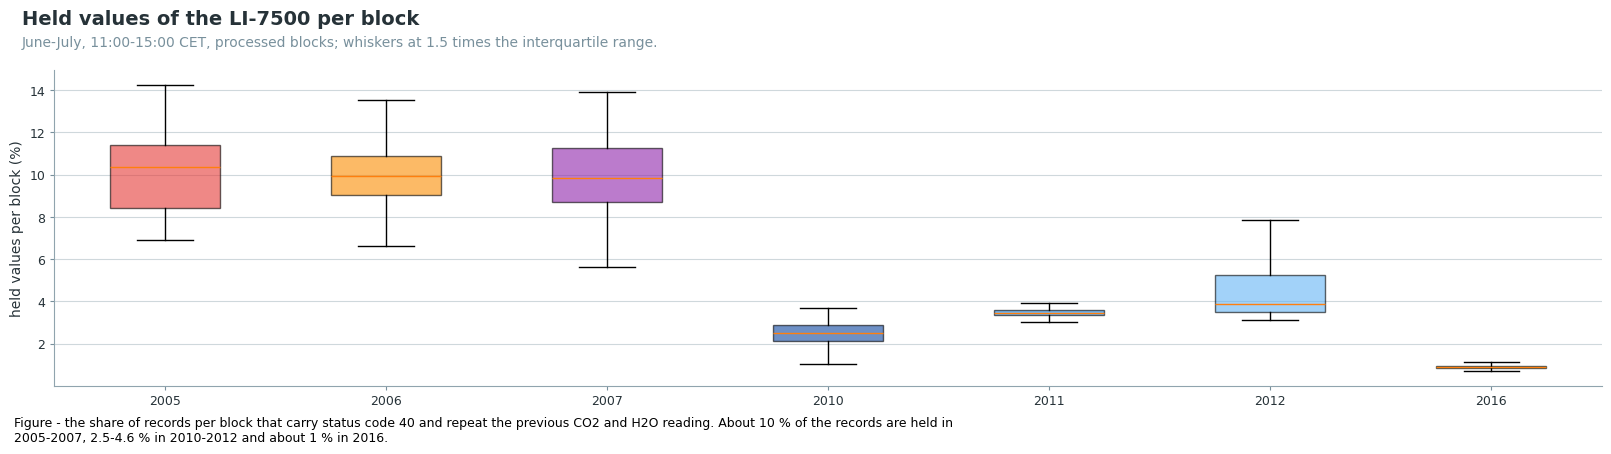

In [7]:
YEAR_COLORS = {2005: cp.TEST_COLORS[0], 2006: cp.TEST_COLORS[1], 2007: cp.TEST_COLORS[2], 2010: '#0d47a1',
               2011: '#1e88e5', 2012: '#64b5f6', 2016: cp.TEST_COLORS[4]}
fig, ax = plt.subplots(figsize=(16, 4.5), layout='constrained')
_data = [100 * OK.loc[OK['year'] == _y, 'status_nonzero_share'].to_numpy() for _y in YEARS]
_bp = ax.boxplot(_data, tick_labels=[str(_y) for _y in YEARS], showfliers=False, patch_artist=True, widths=0.5)
for _patch, _y in zip(_bp['boxes'], YEARS):
    _patch.set_facecolor(YEAR_COLORS[_y])
    _patch.set_alpha(0.6)
ax.set_ylabel('held values per block (%)')
cp.style_axes(ax)
cp.figure_title(fig, 'Held values of the LI-7500 per block',
                'June-July, 11:00-15:00 CET, processed blocks; whiskers at 1.5 times the interquartile range.')
figcap(fig, "the share of records per block that carry status code 40 and repeat the previous CO2 and H2O reading. "
            "About 10 % of the records are held in 2005-2007, 2.5-4.6 % in 2010-2012 and about 1 % in 2016.")
plt.show()

## ⏱️ 3 Time lags

The comparison uses convective blocks: unstable stratification (`z/L` below 0 from the
reprocessing), u* above 0.2 m s-1 and a w-Ts covariance above 0.02 K m s-1. This selection uses
sonic quantities only, so it does not depend on the gas measurement it tests. Values per year are
standardised to the same distribution of `z/L` and u*: the statistic per cell of the two is
averaged with the weights of all selected blocks of all years.

For each block, the covariance of `w` with CO2 and H2O is computed for lags of -2 to +3 s. The lag
of its extremum in the direction of the daytime flux (the minimum for CO2, the maximum for H2O and
sonic temperature) is compared with the EddyPro window (0.05-0.75 s), and the covariance at
the lag EddyPro used with that at the extremum. With noise, the extremum over a wide range is
biased slightly away from zero, so the ratio is a conservative (upper) estimate of the loss from the lag.
The w-Ts covariance is the control: the sonic measures both, so its extremum is at lag 0.

In [8]:
SEL = OK[(OK['zL'] < 0) & (OK['ustar'] > MIN_USTAR) & (OK['cov_used_wt'] > MIN_COV_WT)].copy()
SEL['day'] = SEL.index.normalize()


def cell_of(d):
    return [pd.cut(d['zL'], ZL_BINS), pd.cut(d['ustar'], USTAR_BINS)]


W_CELL = SEL.groupby(cell_of(SEL), observed=True).size()
W_CELL = W_CELL / W_CELL.sum()


def std_value(d, col, how='median'):
    """Statistic of col per cell of z/L and u*, averaged with the weights W_CELL."""
    g = d.groupby(cell_of(d), observed=True)[col]
    m = g.agg(how)[g.size() >= MIN_CELL_N]
    w = W_CELL.reindex(m.index).fillna(0)
    return (m * w).sum() / w.sum() if w.sum() > 0 else np.nan


def std_ratio(d, num, den):
    """Ratio of sums of num and den per cell (a covariance-weighted ratio), averaged with W_CELL."""
    g = d.groupby(cell_of(d), observed=True)
    n = g.size()
    m = (g[num].sum() / g[den].sum())[n >= MIN_CELL_N]
    w = W_CELL.reindex(m.index).fillna(0)
    return (m * w).sum() / w.sum() if w.sum() > 0 else np.nan


def std_apply(d, cols, fn):
    """fn applied to the blocks of each cell of z/L and u*, averaged with the weights W_CELL."""
    g = d.groupby(cell_of(d), observed=True)
    n = g.size()
    m = g[cols].apply(fn)[n >= MIN_CELL_N]
    w = W_CELL.reindex(m.index).fillna(0)
    return (m * w).sum() / w.sum() if w.sum() > 0 else np.nan


# Extremum of the covariance in the direction of the daytime flux (minimum for CO2, maximum for H2O
# and Ts), over the whole scan and within the EddyPro window. Taken on the signed covariance, so
# that a block whose largest excursion has the other sign does not enter with the wrong sign.
_jw = (LAGS >= round(WINDOW[0] * FS)) & (LAGS <= round(WINDOW[1] * FS))
for _t, _sgn in (('wt', 1), ('wc', -1), ('wq', 1)):
    _lc = _sgn * np.stack(SEL[f'lagcov_{_t}'].to_numpy()).astype(float)
    SEL[f'slag_{_t}'] = LAGS[_lc.argmax(axis=1)] / FS
    SEL[f'scov_{_t}'] = _sgn * _lc.max(axis=1)
    SEL[f'scovwin_{_t}'] = _sgn * _lc[:, _jw].max(axis=1)
    # The ratios to the extremum are formed on the blocks whose extremum has the daytime sign; in them
    # the covariance at any lag is closer to zero than at the extremum, so the ratio is at most 1.
    SEL[f'dsign_{_t}'] = _lc.max(axis=1) > 0
for _t in ('wt', 'wc', 'wq'):
    _lag = SEL[f'slag_{_t}']
    SEL[f'out_{_t}'] = ((_lag < WINDOW[0] - 1e-9) | (_lag > WINDOW[1] + 1e-9)).astype(float)
    SEL[f'below_{_t}'] = (_lag < WINDOW[0] - 1e-9).astype(float)
    SEL[f'above_{_t}'] = (_lag > WINDOW[1] + 1e-9).astype(float)
print(f"Selected convective blocks: {len(SEL):,} of {len(OK):,} processed")
print(SEL.groupby('year').size().rename('selected blocks').to_frame().T)
print("\nShare of selected blocks whose covariance extremum has the daytime sign (%):")
print((100 * SEL.groupby('year')[['dsign_wc', 'dsign_wq', 'dsign_wt']].mean()).round(1).T)

Selected convective blocks: 2,533 of 2,730 processed
year             2005  2006  2007  2010  2011  2012  2016
selected blocks   405   437   340   325   308   349   369

Share of selected blocks whose covariance extremum has the daytime sign (%):
year       2005   2006   2007   2010   2011   2012   2016
dsign_wc   98.5   98.2   98.2   99.1   99.4   96.8   97.3
dsign_wq   97.3   97.5   97.9   98.8   98.7   97.1   97.3
dsign_wt  100.0  100.0  100.0  100.0  100.0  100.0  100.0


### 📋 Table: lag of the covariance extremum and covariance at the used lag

In [9]:
_rows = {}
for _y, _g in SEL.groupby('year'):
    _row = {}
    for _t, _name in (('wc', 'CO2'), ('wq', 'H2O')):
        _row[(_name, 'median lag of extremum (s)')] = _g[f'slag_{_t}'].median()
        _row[(_name, 'median used lag (s)')] = _g[f'lag_used_{_t}'].median()
        _row[(_name, 'extremum below window %')] = 100 * std_value(_g, f'below_{_t}', 'mean')
        _row[(_name, 'extremum above window %')] = 100 * std_value(_g, f'above_{_t}', 'mean')
        _gs = _g[_g[f'dsign_{_t}']]
        _row[(_name, 'cov at used lag / cov at extremum')] = std_ratio(_gs, f'cov_used_{_t}', f'scov_{_t}')
        _row[(_name, 'cov at window extremum / cov at extremum')] = std_ratio(_gs, f'scovwin_{_t}', f'scov_{_t}')
    _row[('Ts', 'median lag of extremum (s)')] = _g['slag_wt'].median()
    _row[('Ts', 'extremum at lag 0 %')] = 100 * (_g['slag_wt'] == 0).mean()
    _rows[_y] = _row
LAGTAB = pd.DataFrame(_rows).T
LAGTAB.columns = pd.MultiIndex.from_tuples(LAGTAB.columns)
tabcap("per year, selected blocks: for CO2 and H2O, the median lag of the extremum of the covariance over -2 to "
       "+3 s (the minimum for CO2, the maximum for H2O) and the median lag EddyPro used; the standardised share of blocks whose extremum lies below or "
       "above the EddyPro window of 0.05-0.75 s; and the standardised covariance-weighted ratio of the covariance "
       "at the used lag, and at the extremum within the window, to the covariance at the extremum, over the blocks "
       "whose extremum has the daytime sign. For sonic "
       "temperature, the median lag of the extremum and the share of blocks with the extremum at lag 0")
display(LAGTAB.round(3))

Table - per year, selected blocks: for CO2 and H2O, the median lag of the extremum of the covariance
over -2 to +3 s (the minimum for CO2, the maximum for H2O) and the median lag EddyPro used; the
standardised share of blocks whose extremum lies below or above the EddyPro window of 0.05-0.75 s;
and the standardised covariance-weighted ratio of the covariance at the used lag, and at the
extremum within the window, to the covariance at the extremum, over the blocks whose extremum has
the daytime sign. For sonic temperature, the median lag of the extremum and the share of blocks with
the extremum at lag 0



CO2                                                                                                                                                                       H2O                                                                                                                                                                        Ts                    
     median lag of extremum (s) median used lag (s) extremum below window % extremum above window % cov at used lag / cov at extremum cov at window extremum / cov at extremum median lag of extremum (s) median used lag (s) extremum below window % extremum above window % cov at used lag / cov at extremum cov at window extremum / cov at extremum median lag of extremum (s) extremum at lag 0 %
2005                       0.25                0.25                   2.792                   0.846                             1.000                                    1.000                       0.30                0.30                   4.937                   1.730                             1.000                                    1.000                        0.0              89.383
2006                       0.25                0.25                   3.751                   0.853                             0.999                                    0.999                       0.30                0.25                   4.360                   0.934                             1.000                                    1.000                        0.0              91.533
2007                       0.25                0.25                   4.044                   1.310                             0.997                                    0.999                       0.25                0.25                   4.542                   0.802                             0.999                                    0.999                        0.0              88.824
2010                       0.30                0.30                   0.316                   1.060                             0.999                                    1.000                       0.30                0.30                   4.484                   1.019                             1.000                                    1.000                        0.0              88.000
2011                       0.30                0.30                   0.949                   0.000                             1.000                                    1.000                       0.30                0.30                   3.396                   0.352                             1.000                                    1.000                        0.0              90.909
2012                       0.30                0.30                   2.930                   1.955                             0.988                                    0.991                       0.30                0.30                   3.063                   1.798                             0.998                                    0.999                        0.0              88.539
2016                       0.30                0.30                   3.016                   1.490                             0.996                                    0.997                       0.30                0.30                   3.211                   0.496                             1.000                                    1.000                        0.0              89.702

### 📊 Plot: median covariance-lag functions per year

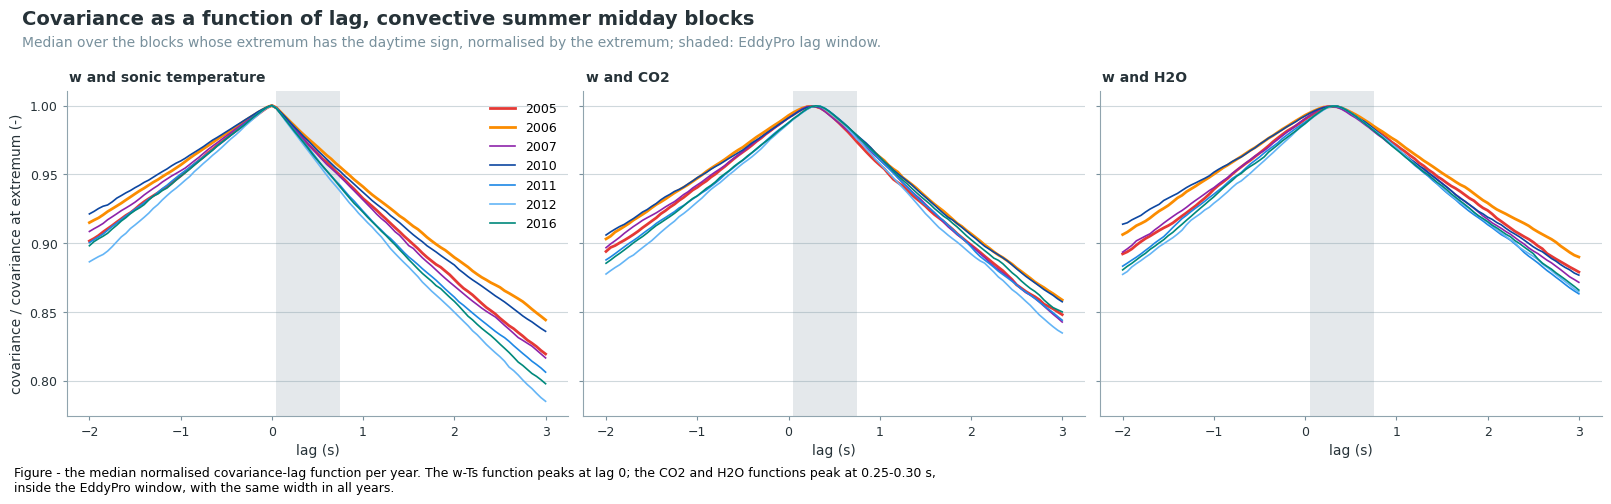

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5), sharey=True, layout='constrained')
_x = LAGS / FS
for _ax, (_t, _title) in zip(axs, (('wt', 'w and sonic temperature'), ('wc', 'w and CO2'), ('wq', 'w and H2O'))):
    for _y in YEARS:
        _g = SEL[SEL['year'] == _y]
        _g = _g[_g[f'dsign_{_t}']]
        _c = np.stack(_g[f'lagcov_{_t}'].to_numpy()) / _g[f'scov_{_t}'].to_numpy()[:, None]
        _early = _y in EARLY
        _ax.plot(_x, np.median(_c, axis=0), color=YEAR_COLORS[_y], linewidth=2.0 if _early else 1.2, label=str(_y))
    _ax.axvspan(*WINDOW, color=cp.MUTED, alpha=0.2, linewidth=0)
    _ax.set_xlabel('lag (s)')
    cp.style_axes(_ax)
    cp.panel_label(_ax, _title)
axs[0].set_ylabel('covariance / covariance at extremum (-)')
axs[0].legend(frameon=False, fontsize=9, loc='upper right')
cp.figure_title(fig, 'Covariance as a function of lag, convective summer midday blocks',
                'Median over the blocks whose extremum has the daytime sign, normalised by the extremum; shaded: EddyPro lag window.')
figcap(fig, "the median normalised covariance-lag function per year. The w-Ts function peaks at lag 0; the CO2 and H2O "
            "functions peak at 0.25-0.30 s, inside the EddyPro window, with the same width in all years.")
plt.show()

## 📈 4 Cospectra

The gas series are shifted by the lag EddyPro used. Per block, the cospectra are summed in
log-spaced frequency bins and divided by the covariance, so that each block contributes the
shape of its cospectrum. A loss of high frequencies in the gas measurement shows as a gas
cospectrum that falls off earlier than the w-Ts cospectrum, and as a smaller share of the gas
covariance at high frequencies.

**Spectral attenuation estimate.** If CO2 and H2O have the shape of the w-Ts cospectrum below
`F_HF_MAIN` (0.1 Hz) and the measurement attenuates only above it, the measured gas covariance
relative to the unattenuated one is `A = (1 - φ_T) / (1 - φ_gas)`, where `φ` is the share of each
covariance above 0.1 Hz. The shares are formed from the cospectra summed over the blocks of each
cell of `z/L` and u*, so that blocks with a small covariance do not dominate. `A` includes the dissimilarity of the scalars at high frequencies and the
path averaging of the sonic, so its absolute value is not the attenuation; differences of `A`
between years are.

In [11]:
_hi = {f0: EDGES[:-1] >= f0 for f0 in F_HF}
for _t in ('wt', 'wc', 'wq'):
    _C = np.stack(SEL[f'cosp_{_t}'].to_numpy()).astype(float)
    _tot = _C.sum(axis=1)
    SEL[f'cospn_{_t}'] = list(_C / _tot[:, None])
    SEL[f'cosum_{_t}'] = _tot
    for _f0, _m in _hi.items():
        SEL[f'hf{_f0}_{_t}'] = _C[:, _m].sum(axis=1)


def hf_share(t, f0):
    """Share of the summed covariance of a group of blocks above f0 (a covariance-weighted share)."""
    return lambda q: q[f'hf{f0}_{t}'].sum() / q[f'cosum_{t}'].sum()


def attenuation(t):
    """Spectral attenuation estimate A of gas t relative to sonic temperature, from the summed cospectra."""
    return lambda q: (1 - hf_share('wt', F_HF_MAIN)(q)) / (1 - hf_share(t, F_HF_MAIN)(q))


HF_COLS = [c for c in SEL.columns if c.startswith('hf') or c.startswith('cosum_')]
DLNF = np.diff(np.log(EDGES))


# Bins that hold no Fourier frequency (the lowest bins are narrower than the frequency resolution).
EMPTY_BINS = (np.stack(SEL['spec_w'].to_numpy()) == 0).all(axis=0)


def median_curve(d, col):
    """Median over the blocks of an array column, with the empty bins set to NaN."""
    return np.where(EMPTY_BINS, np.nan, np.median(np.stack(d[col].to_numpy()), axis=0))

### 📊 Plot: normalised cospectra per year

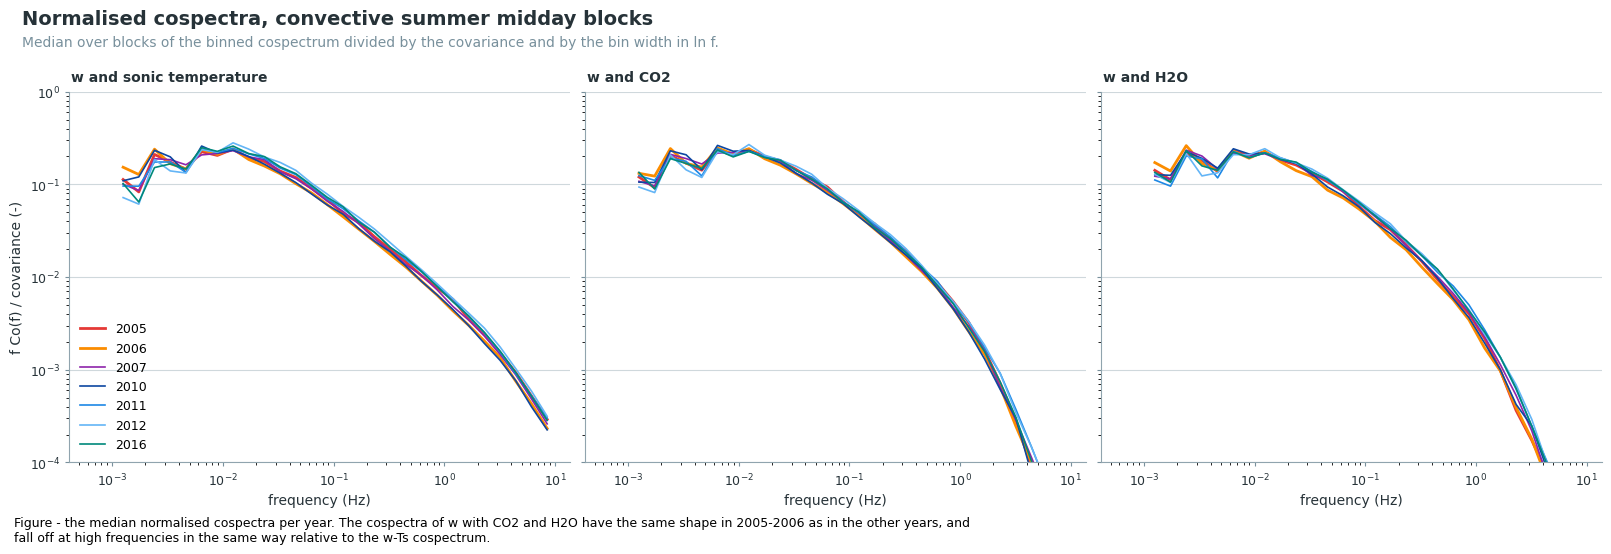

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5.5), sharey=True, layout='constrained')
for _ax, (_t, _title) in zip(axs, (('wt', 'w and sonic temperature'), ('wc', 'w and CO2'), ('wq', 'w and H2O'))):
    for _y in YEARS:
        _g = SEL[SEL['year'] == _y]
        _ax.plot(FC, median_curve(_g, f'cospn_{_t}') / DLNF, color=YEAR_COLORS[_y],
                 linewidth=2.0 if _y in EARLY else 1.2, label=str(_y))
    _ax.set_xscale('log')
    _ax.set_yscale('log')
    _ax.set_ylim(1e-4, 1)
    _ax.set_xlabel('frequency (Hz)')
    cp.style_axes(_ax)
    cp.panel_label(_ax, _title)
axs[0].set_ylabel('f Co(f) / covariance (-)')
axs[0].legend(frameon=False, fontsize=9, loc='lower left')
cp.figure_title(fig, 'Normalised cospectra, convective summer midday blocks',
                'Median over blocks of the binned cospectrum divided by the covariance and by the bin width in ln f.')
figcap(fig, "the median normalised cospectra per year. The cospectra of w with CO2 and H2O have the same shape in "
            "2005-2006 as in the other years, and fall off at high frequencies in the same way relative to the w-Ts "
            "cospectrum.")
plt.show()

### 📊 Plot: ratio of the gas cospectra to the w-Ts cospectrum per frequency bin

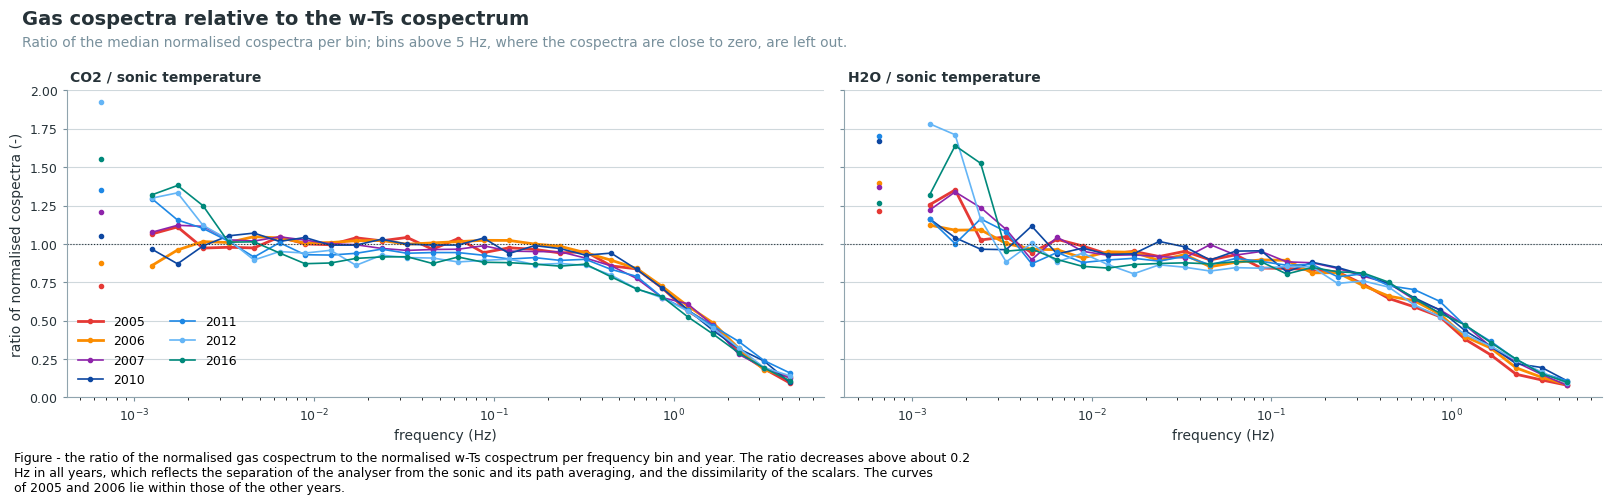

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5), sharey=True, layout='constrained')
_ok = FC < 5
for _ax, (_t, _title) in zip(axs, (('wc', 'CO2 / sonic temperature'), ('wq', 'H2O / sonic temperature'))):
    for _y in YEARS:
        _g = SEL[SEL['year'] == _y]
        _ratio = median_curve(_g, f'cospn_{_t}') / median_curve(_g, 'cospn_wt')
        _ax.plot(FC[_ok], _ratio[_ok], color=YEAR_COLORS[_y], linewidth=2.0 if _y in EARLY else 1.2, label=str(_y),
                 marker='o', markersize=3)
    _ax.axhline(1, color=cp.INK, linewidth=0.8, linestyle=':')
    _ax.set_xscale('log')
    _ax.set_ylim(0, 2)
    _ax.set_xlabel('frequency (Hz)')
    cp.style_axes(_ax)
    cp.panel_label(_ax, _title)
axs[0].set_ylabel('ratio of normalised cospectra (-)')
axs[0].legend(frameon=False, fontsize=9, loc='lower left', ncol=2)
cp.figure_title(fig, 'Gas cospectra relative to the w-Ts cospectrum',
                'Ratio of the median normalised cospectra per bin; bins above 5 Hz, where the cospectra are close to zero, are left out.')
figcap(fig, "the ratio of the normalised gas cospectrum to the normalised w-Ts cospectrum per frequency bin and year. "
            "The ratio decreases above about 0.2 Hz in all years, which reflects the separation of the analyser from "
            "the sonic and its path averaging, and the dissimilarity of the scalars. The curves of 2005 and 2006 lie "
            "within those of the other years.")
plt.show()

### 📊 Plot: normalised ogives per year

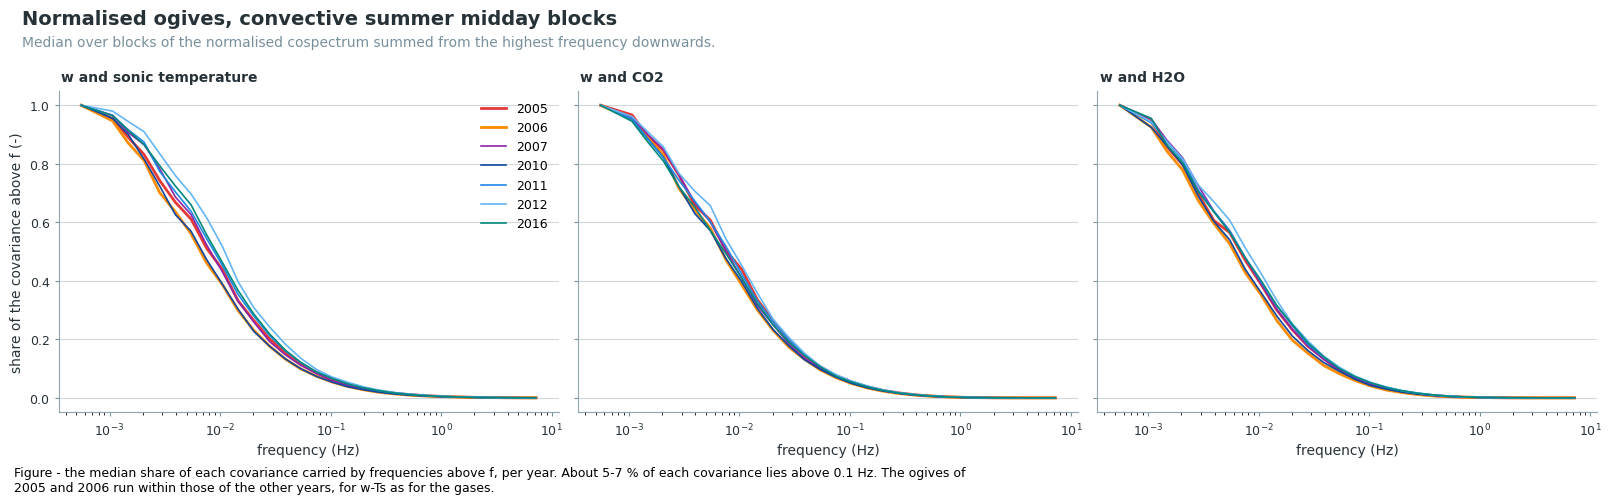

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5), sharey=True, layout='constrained')
for _ax, (_t, _title) in zip(axs, (('wt', 'w and sonic temperature'), ('wc', 'w and CO2'), ('wq', 'w and H2O'))):
    for _y in YEARS:
        _g = SEL[SEL['year'] == _y]
        _og = np.median(np.cumsum(np.stack(_g[f'cospn_{_t}'].to_numpy())[:, ::-1], axis=1)[:, ::-1], axis=0)
        _ax.plot(EDGES[:-1][~EMPTY_BINS], _og[~EMPTY_BINS], color=YEAR_COLORS[_y], linewidth=2.0 if _y in EARLY else 1.2, label=str(_y))
    _ax.set_xscale('log')
    _ax.set_xlabel('frequency (Hz)')
    cp.style_axes(_ax)
    cp.panel_label(_ax, _title)
axs[0].set_ylabel('share of the covariance above f (-)')
axs[0].legend(frameon=False, fontsize=9, loc='upper right')
cp.figure_title(fig, 'Normalised ogives, convective summer midday blocks',
                'Median over blocks of the normalised cospectrum summed from the highest frequency downwards.')
figcap(fig, "the median share of each covariance carried by frequencies above f, per year. About 5-7 % of each "
            "covariance lies above 0.1 Hz. The ogives of 2005 and 2006 run within those of the other years, for w-Ts "
            "as for the gases.")
plt.show()

### 📋 Table: high-frequency shares of the covariances and spectral attenuation estimate

In [15]:
_rows = {}
for _y, _g in SEL.groupby('year'):
    _row = {}
    for _f0 in F_HF:
        for _t, _name in (('wt', 'Ts'), ('wc', 'CO2'), ('wq', 'H2O')):
            _row[(f'share above {_f0} Hz', _name)] = std_apply(_g, HF_COLS, hf_share(_t, _f0))
    for _t, _name in (('wc', 'CO2'), ('wq', 'H2O')):
        _row[('A', _name)] = std_apply(_g, HF_COLS, attenuation(_t))
    _row[('wind speed', 'm s-1')] = std_value(_g, 'wind_speed')
    _rows[_y] = _row
SPECTAB = pd.DataFrame(_rows).T
SPECTAB.columns = pd.MultiIndex.from_tuples(SPECTAB.columns)
_aref = SPECTAB.loc[REF, 'A'].mean()
for _name in ('CO2', 'H2O'):
    SPECTAB[('A relative to 2010-2012', _name)] = SPECTAB[('A', _name)] / _aref[_name]
tabcap("per year, selected blocks, standardised to the same z/L and u*: the covariance-weighted share of the covariance of w with "
       "sonic temperature, CO2 and H2O above 0.1, 0.3 and 1 Hz; the spectral attenuation estimate A of CO2 and H2O "
       "relative to sonic temperature (above 0.1 Hz) and relative to its mean over 2010-2012; and the median wind "
       "speed")
display(SPECTAB.round(4))

Table - per year, selected blocks, standardised to the same z/L and u*: the covariance-weighted
share of the covariance of w with sonic temperature, CO2 and H2O above 0.1, 0.3 and 1 Hz; the
spectral attenuation estimate A of CO2 and H2O relative to sonic temperature (above 0.1 Hz) and
relative to its mean over 2010-2012; and the median wind speed



share above 0.1 Hz                 share above 0.3 Hz                 share above 1.0 Hz                       A         wind speed A relative to 2010-2012        
                     Ts     CO2     H2O                 Ts     CO2     H2O                 Ts     CO2     H2O     CO2     H2O      m s-1                     CO2     H2O
2005             0.0651  0.0561  0.0385             0.0167  0.0111  0.0072             0.0052  0.0022  0.0013  0.9906  0.9746     2.0012                  1.0048  0.9892
2006             0.0579  0.0594  0.0422             0.0148  0.0106  0.0073             0.0045  0.0015  0.0013  1.0022  0.9839     1.9638                  1.0166  0.9986
2007             0.0710  0.0483  0.0573             0.0181  0.0093  0.0109             0.0058  0.0020  0.0022  0.9765  0.9857     2.2193                  0.9905  1.0004
2010             0.0588  0.0529  0.0476             0.0147  0.0105  0.0090             0.0043  0.0019  0.0016  0.9938  0.9883     2.0234                  1.0080  1.0031
2011             0.0754  0.0631  0.0594             0.0196  0.0134  0.0120             0.0060  0.0029  0.0024  0.9868  0.9829     2.2679                  1.0009  0.9976
2012             0.0766  0.0550  0.0615             0.0205  0.0110  0.0125             0.0070  0.0025  0.0025  0.9770  0.9847     2.3019                  0.9910  0.9993
2016             0.0721  0.0713  0.0574             0.0194  0.0153  0.0114             0.0066  0.0027  0.0022  0.9997  0.9843     2.2111                  1.0141  0.9990

## 🔊 5 Instrument noise

White noise adds to the autocovariance at lag 0 only. The noise variance is estimated as the
variance minus the autocovariance extrapolated to lag 0 with a straight line through lags of 1-3
samples (the main estimate). The variance minus the autocovariance at lag 1 is an upper bound,
since it also includes the turbulent decorrelation over one sample (50 ms). Noise lowers the
correlation coefficient by the factor `sqrt(1 - noise share)` and does not change the covariance.

### 📋 Table: noise share of the variances and its effect on the correlation coefficients

In [16]:
for _k in ('w', 'ts', 'co2', 'h2o'):
    SEL[f'ns_{_k}'] = SEL[f'noise_var_{_k}'] / SEL[f'var_{_k}']
    SEL[f'nsmax_{_k}'] = SEL[f'noise_var_max_{_k}'] / SEL[f'var_{_k}']
_fac = lambda k, col: 1 / np.sqrt(1 - SEL[f'{col}_{k}'].clip(lower=0))
for _t, _k in (('wc', 'co2'), ('wq', 'h2o')):
    SEL[f'rn_{_t}'] = SEL[f'r_{_t}'] * _fac(_k, 'ns') * _fac('w', 'ns')
    SEL[f'rnmax_{_t}'] = SEL[f'r_{_t}'] * _fac(_k, 'nsmax') * _fac('w', 'nsmax')
SEL['rn_wt'] = SEL['r_wt'] * _fac('ts', 'ns') * _fac('w', 'ns')
SEL['rn_cq'] = SEL['r_cq'] * _fac('co2', 'ns') * _fac('h2o', 'ns')
SEL['rnmax_cq'] = SEL['r_cq'] * _fac('co2', 'nsmax') * _fac('h2o', 'nsmax')
_rows = {}
for _y, _g in SEL.groupby('year'):
    _row = {}
    for _k, _name in (('w', 'w'), ('ts', 'Ts'), ('co2', 'CO2'), ('h2o', 'H2O')):
        _row[('noise share %', _name)] = 100 * std_value(_g, f'ns_{_k}')
    for _k, _name in (('co2', 'CO2'), ('h2o', 'H2O')):
        _row[('upper bound %', _name)] = 100 * std_value(_g, f'nsmax_{_k}')
    for _t, _name in (('wc', 'r(w,CO2)'), ('wq', 'r(w,H2O)'), ('cq', 'r(CO2,H2O)')):
        _row[('rise of r without noise %', _name)] = 100 * (std_value(_g, f'rn_{_t}') / std_value(_g, f'r_{_t}') - 1)
        _row[('rise of r, upper bound %', _name)] = 100 * (std_value(_g, f'rnmax_{_t}') / std_value(_g, f'r_{_t}') - 1)
    _rows[_y] = _row
NOISE = pd.DataFrame(_rows).T
NOISE.columns = pd.MultiIndex.from_tuples(NOISE.columns)
tabcap("per year, selected blocks, standardised medians: the noise variance as a share of the variance of w, sonic "
       "temperature, CO2 and H2O (main estimate; slightly negative values mean no detectable white noise), the upper "
       "bound for CO2 and H2O, and the rise of the correlation coefficients when the noise is removed from the "
       "variances, for the main estimate and the upper bound")
display(NOISE.round(3))

Table - per year, selected blocks, standardised medians: the noise variance as a share of the
variance of w, sonic temperature, CO2 and H2O (main estimate; slightly negative values mean no
detectable white noise), the upper bound for CO2 and H2O, and the rise of the correlation
coefficients when the noise is removed from the variances, for the main estimate and the upper bound



noise share %                      upper bound %        rise of r without noise % rise of r, upper bound % rise of r without noise % rise of r, upper bound % rise of r without noise % rise of r, upper bound %
                 w     Ts    CO2    H2O           CO2    H2O                  r(w,CO2)                 r(w,CO2)                  r(w,H2O)                 r(w,H2O)                r(CO2,H2O)               r(CO2,H2O)
2005        -0.150 -0.152  0.143  0.010         0.848  0.609                     0.102                    1.057                     0.027                    0.964                     0.203                    0.960
2006        -0.139 -0.146  0.148  0.015         0.821  0.576                     0.106                    1.144                     0.018                    0.809                     0.922                    1.591
2007        -0.140 -0.161  0.121  0.008         0.902  0.674                     0.098                    1.200                     0.007                    0.858                     0.179                    1.061
2010        -0.142 -0.150  0.111  0.007         0.786  0.617                     0.154                    0.972                     0.004                    0.807                     0.174                    1.001
2011        -0.140 -0.180  0.087  0.002         0.943  0.768                     0.325                    1.430                     0.059                    1.042                     0.155                    1.237
2012        -0.151 -0.169  0.082 -0.007         0.882  0.747                     0.280                    1.502                     0.038                    1.105                     0.151                    0.894
2016        -0.153 -0.180  0.050 -0.032         0.884  0.720                     0.080                    1.048                     0.008                    0.876                     0.238                    1.076

### 📊 Plot: normalised power spectra of CO2, H2O and sonic temperature

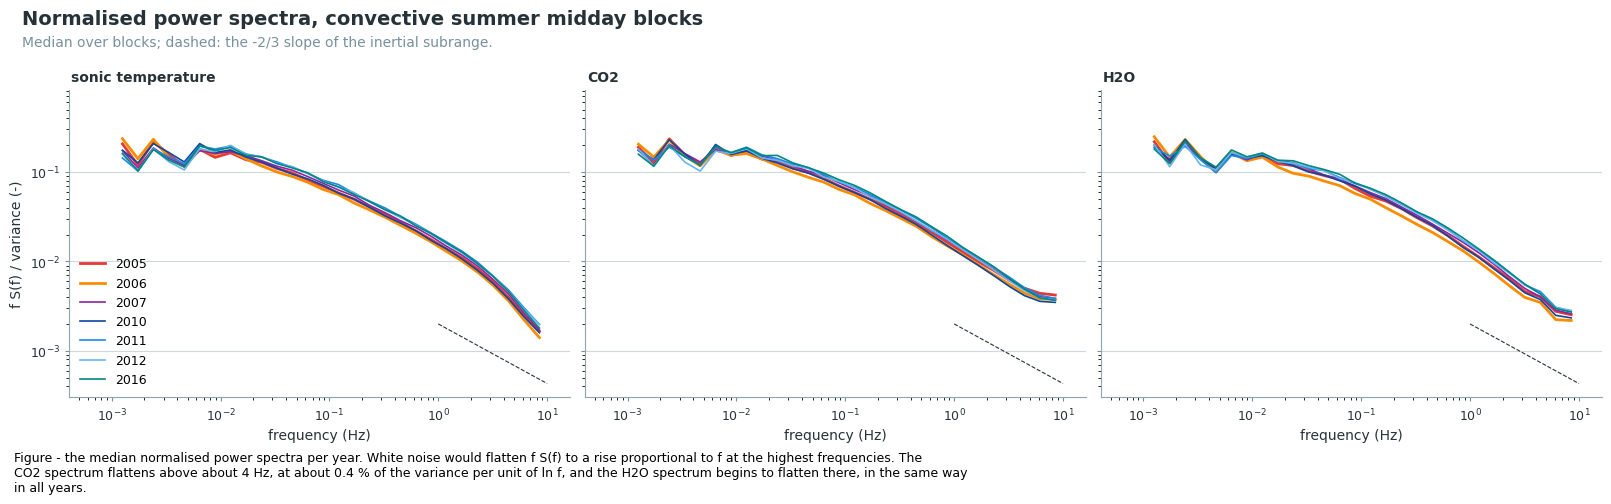

In [17]:
for _k in ('ts', 'co2', 'h2o'):
    _S = np.stack(SEL[f'spec_{_k}'].to_numpy()).astype(float)
    SEL[f'specn_{_k}'] = list(_S / _S.sum(axis=1)[:, None])
fig, axs = plt.subplots(1, 3, figsize=(16, 5), sharey=True, layout='constrained')
for _ax, (_k, _title) in zip(axs, (('ts', 'sonic temperature'), ('co2', 'CO2'), ('h2o', 'H2O'))):
    for _y in YEARS:
        _g = SEL[SEL['year'] == _y]
        _ax.plot(FC, median_curve(_g, f'specn_{_k}') / DLNF, color=YEAR_COLORS[_y],
                 linewidth=2.0 if _y in EARLY else 1.2, label=str(_y))
    _f = np.array([1.0, 10.0])
    _ax.plot(_f, 2e-3 * _f ** (-2 / 3), color=cp.INK, linewidth=0.8, linestyle='--')
    _ax.set_xscale('log')
    _ax.set_yscale('log')
    _ax.set_xlabel('frequency (Hz)')
    cp.style_axes(_ax)
    cp.panel_label(_ax, _title)
axs[0].set_ylabel('f S(f) / variance (-)')
axs[0].legend(frameon=False, fontsize=9, loc='lower left')
cp.figure_title(fig, 'Normalised power spectra, convective summer midday blocks',
                'Median over blocks; dashed: the -2/3 slope of the inertial subrange.')
figcap(fig, "the median normalised power spectra per year. White noise would flatten f S(f) to a rise proportional to f "
            "at the highest frequencies. The CO2 spectrum flattens above about 4 Hz, at about 0.4 % of the variance per "
            "unit of ln f, and the H2O spectrum begins to flatten there, in the same way in all years.")
plt.show()

## 🔗 6 Correlation coefficients at matched stability and u*

For the selected blocks, the correlation coefficients of `w` with sonic temperature (`r_wt`), CO2
(`r_wc`) and H2O (`r_wq`), and of CO2 with H2O (`r_cq`, at lag 0, since both are measured in the
same path), standardised to the same `z/L` and u*. Signs are chosen so that all coefficients are
positive in summer daytime. The 5-95 % ranges relative to 2010-2012 come from resampling the days
of each year (`N_BOOT` resamples).

In [18]:
RCOLS = ['r_wt', 'r_wc', 'r_wq', 'r_cq']
CORR = pd.DataFrame({_y: {**{'blocks': len(_g)}, **{_c: std_value(_g, _c) for _c in RCOLS},
                          **{f'{_c} without noise': std_value(_g, f'rn_{_c[2:]}') for _c in RCOLS}}
                     for _y, _g in SEL.groupby('year')}).T
REL = CORR[RCOLS] / CORR.loc[REF, RCOLS].mean()

_rng = np.random.default_rng(SEED)
_day_rows = {_y: [np.flatnonzero(_g['day'].to_numpy() == _d) for _d in _g['day'].unique()]
             for _y, _g in SEL.groupby('year')}
_years_g = {_y: _g for _y, _g in SEL.groupby('year')}
_boot = []
for _b in range(N_BOOT):
    _v = {}
    for _y, _g in _years_g.items():
        _rows_d = _day_rows[_y]
        _pick = _rng.integers(0, len(_rows_d), len(_rows_d))
        _q = _g.iloc[np.concatenate([_rows_d[_i] for _i in _pick])]
        _v[_y] = {_c: std_value(_q, _c) for _c in RCOLS}
    _v = pd.DataFrame(_v).T
    _boot.append(_v / _v.loc[REF].mean())
_boot = pd.concat(_boot, keys=range(N_BOOT))
REL_LO = _boot.groupby(level=1).quantile(0.05)
REL_HI = _boot.groupby(level=1).quantile(0.95)

### 📋 Table: correlation coefficients per year, raw and without noise

In [19]:
tabcap("per year, the number of selected blocks and the standardised correlation coefficients of w with sonic "
       "temperature, CO2 and H2O and of CO2 with H2O, as measured and with the noise variance (main estimate) "
       "removed from the variances")
display(CORR.round(3))

Table - per year, the number of selected blocks and the standardised correlation coefficients of w
with sonic temperature, CO2 and H2O and of CO2 with H2O, as measured and with the noise variance
(main estimate) removed from the variances



,blocks,r_wt,r_wc,r_wq,r_cq,r_wt without noise,r_wc without noise,r_wq without noise,r_cq without noise
2005,405.0,0.504,0.488,0.409,0.773,0.504,0.489,0.409,0.775
2006,437.0,0.502,0.486,0.399,0.731,0.502,0.486,0.399,0.738
2007,340.0,0.511,0.504,0.437,0.830,0.511,0.504,0.437,0.831
2010,325.0,0.502,0.503,0.420,0.812,0.502,0.503,0.420,0.813
2011,308.0,0.517,0.523,0.445,0.844,0.517,0.525,0.445,0.845
2012,349.0,0.496,0.477,0.428,0.861,0.496,0.478,0.428,0.863
2016,369.0,0.497,0.513,0.465,0.838,0.497,0.514,0.465,0.840


### 📋 Table: correlation coefficients relative to 2010-2012, with 5-95 % ranges

In [20]:
_t = pd.concat({'relative': REL, '5 %': REL_LO, '95 %': REL_HI}, axis=1).swaplevel(axis=1)
_t = _t[[(_c, _s) for _c in RCOLS for _s in ('relative', '5 %', '95 %')]]
tabcap("per year, the standardised correlation coefficients divided by their mean over 2010-2012, with the 5 and "
       "95 % quantiles of the ratio over resamples of the days of each year")
display(_t.round(3))

Table - per year, the standardised correlation coefficients divided by their mean over 2010-2012,
with the 5 and 95 % quantiles of the ratio over resamples of the days of each year



r_wt                   r_wc                   r_wq                   r_cq              
     relative    5 %   95 % relative    5 %   95 % relative    5 %   95 % relative    5 %   95 %
2005    0.997  0.977  1.033    0.975  0.932  1.010    0.950  0.911  0.998    0.921  0.871  0.969
2006    0.995  0.966  1.032    0.970  0.936  1.009    0.926  0.881  0.971    0.872  0.792  0.922
2007    1.013  0.973  1.043    1.005  0.964  1.038    1.014  0.964  1.061    0.989  0.940  1.026
2010    0.994  0.975  1.017    1.003  0.983  1.032    0.975  0.938  1.007    0.968  0.929  0.993
2011    1.023  1.001  1.047    1.045  1.016  1.062    1.033  1.001  1.064    1.006  0.984  1.031
2012    0.983  0.958  1.000    0.952  0.926  0.981    0.993  0.960  1.021    1.027  1.005  1.056
2016    0.984  0.946  1.014    1.025  0.980  1.049    1.078  1.026  1.124    0.998  0.966  1.039

### 📊 Plot: correlation coefficients relative to 2010-2012

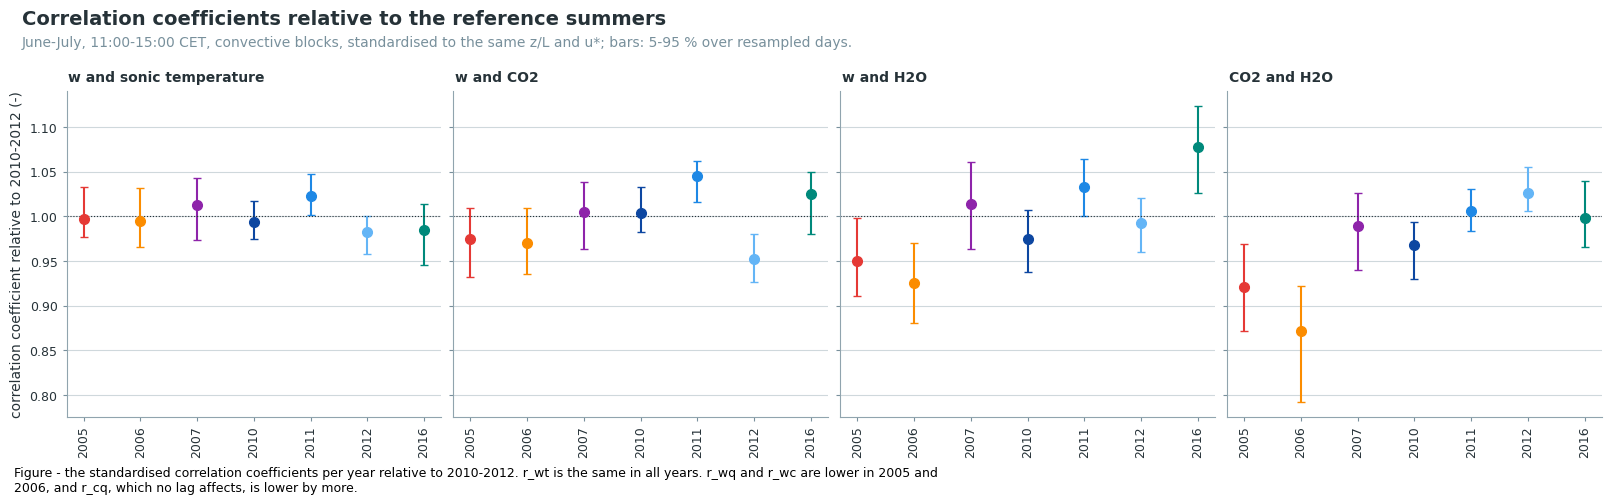

In [21]:
fig, axs = plt.subplots(1, 4, figsize=(16, 5), sharey=True, layout='constrained')
for _ax, _c, _title in zip(axs, RCOLS, ('w and sonic temperature', 'w and CO2', 'w and H2O', 'CO2 and H2O')):
    for _i, _y in enumerate(YEARS):
        _ax.errorbar(_i, REL.loc[_y, _c], yerr=[[REL.loc[_y, _c] - REL_LO.loc[_y, _c]], [REL_HI.loc[_y, _c] - REL.loc[_y, _c]]],
                     marker='o', markersize=7, color=YEAR_COLORS[_y], capsize=3, linestyle='none')
    _ax.axhline(1, color=cp.INK, linewidth=0.8, linestyle=':')
    _ax.set_xticks(range(len(YEARS)), [str(_y) for _y in YEARS], rotation=90)
    cp.style_axes(_ax)
    cp.panel_label(_ax, _title)
axs[0].set_ylabel('correlation coefficient relative to 2010-2012 (-)')
cp.figure_title(fig, 'Correlation coefficients relative to the reference summers',
                'June-July, 11:00-15:00 CET, convective blocks, standardised to the same z/L and u*; bars: 5-95 % over resampled days.')
figcap(fig, "the standardised correlation coefficients per year relative to 2010-2012. r_wt is the same in all years. "
            "r_wq and r_wc are lower in 2005 and 2006, and r_cq, which no lag affects, is lower by more.")
plt.show()

## ⚖️ 7 Attribution

The reduction of the correlation of `w` with each gas in 2005-2006, relative to 2010-2012, is set
against the parts of it that the measurement accounts for, each relative to the same reference:

- **Lag:** the change of the ratio of the covariance at the used lag to that at the extremum.
- **Spectral:** the change of the attenuation estimate `A`.
- **Held values:** the share of held records times the relative loss of covariance from a shift
  of one sample at the used lag, `1 - cov(L - 1) / cov(L)`, against the same for the reference.
- **Noise:** the change of the rise of the correlation when the noise is removed.

The first three lower the covariance; noise lowers only the correlation. Negative values are
losses relative to 2010-2012.

In [22]:
for _t in ('wc', 'wq'):
    _lc = np.stack(SEL[f'lagcov_{_t}'].to_numpy()).astype(float)
    _j = np.round(SEL[f'lag_used_{_t}'].to_numpy() * FS).astype(int) - LAGS[0]
    _i = np.arange(len(_j))
    SEL[f'hold_{_t}'] = SEL['status_nonzero_share'] * (1 - _lc[_i, _j - 1] / _lc[_i, _j])


def components(d, t):
    return {'r': std_value(d, f'r_{t}'),
            'lag': std_ratio(d[d[f'dsign_{t}']], f'cov_used_{t}', f'scov_{t}'),
            'spectral': std_apply(d, HF_COLS, attenuation(t)),
            'held': 1 - std_value(d, f'hold_{t}', 'mean'),
            'noise': std_value(d, f'r_{t}') / std_value(d, f'rn_{t}')}


_rows = {}
for _t, _name in (('wc', 'CO2'), ('wq', 'H2O')):
    _c = pd.DataFrame({_y: components(_g, _t) for _y, _g in SEL.groupby('year')}).T
    _rel = 100 * (_c / _c.loc[REF].mean() - 1)
    _rel['measurement, covariance'] = _rel[['lag', 'spectral', 'held']].sum(axis=1)
    _rel['measurement, correlation'] = _rel['measurement, covariance'] + _rel['noise']
    _rel['not explained'] = _rel['r'] - _rel['measurement, correlation']
    _rows[_name] = _rel
ATTR = pd.concat(_rows, axis=1)
ATTR = ATTR.rename(columns={'r': 'correlation'}, level=1)
HELD_LOSS = pd.DataFrame({_name: 100 * SEL.groupby('year')[f'hold_{_t}'].mean()
                          for _t, _name in (('wc', 'CO2'), ('wq', 'H2O'))})
print("Covariance lost to held values (%, mean of blocks):")
print(HELD_LOSS.round(4).T)

Covariance lost to held values (%, mean of blocks):
year    2005    2006    2007    2010    2011    2012    2016
CO2   0.0073  0.0054  0.0058  0.0014  0.0030  0.0000 -0.0032
H2O   0.0076  0.0027  0.0045  0.0000  0.0033  0.0029  0.0005


### 📋 Table: change of the correlation and the parts the measurement accounts for

In [23]:
tabcap("per year and gas, in % relative to the mean of 2010-2012 (negative: lower): the change of the standardised "
       "correlation of w with the gas; the changes from the lag, the spectral attenuation estimate, the held values "
       "and the noise; their sum without the noise (the change of the covariance caused by the measurement) and with "
       "it (the change of the correlation caused by the measurement); and the part of the change of the correlation "
       "that the measurement does not account for")
display(ATTR.round(2))

Table - per year and gas, in % relative to the mean of 2010-2012 (negative: lower): the change of
the standardised correlation of w with the gas; the changes from the lag, the spectral attenuation
estimate, the held values and the noise; their sum without the noise (the change of the covariance
caused by the measurement) and with it (the change of the correlation caused by the measurement);
and the part of the change of the correlation that the measurement does not account for



CO2                                                                                                  H2O                                                                                         
     correlation   lag spectral held noise measurement, covariance measurement, correlation not explained correlation   lag spectral held noise measurement, covariance measurement, correlation not explained
2005       -2.49  0.40     0.48 -0.0  0.15                    0.87                     1.03         -3.52       -5.01  0.04    -1.08 -0.0  0.01                   -1.05                    -1.04         -3.97
2006       -3.02  0.27     1.66 -0.0  0.15                    1.93                     2.07         -5.10       -7.44  0.04    -0.14 -0.0  0.02                   -0.09                    -0.08         -7.37
2007        0.53  0.13    -0.95 -0.0  0.15                   -0.82                    -0.66          1.19        1.39 -0.08     0.04 -0.0  0.03                   -0.04                    -0.01          1.40
2010        0.34  0.35     0.80  0.0  0.10                    1.16                     1.26         -0.91       -2.53  0.04     0.31  0.0  0.03                    0.35                     0.38         -2.91
2011        4.48  0.40     0.09 -0.0 -0.07                    0.50                     0.43          4.05        3.25  0.06    -0.24 -0.0 -0.03                   -0.19                    -0.21          3.47
2012       -4.82 -0.76    -0.90  0.0 -0.03                   -1.65                    -1.68         -3.14       -0.72 -0.10    -0.07 -0.0 -0.00                   -0.16                    -0.17         -0.56
2016        2.48  0.05     1.41  0.0  0.17                    1.46                     1.64          0.85        7.80  0.04    -0.10  0.0  0.03                   -0.06                    -0.03          7.83

## 📝 Findings

All numbers refer to June-July, 11:00-15:00 CET, convective blocks (2,533 of 2,730 processed
blocks), standardised to the same `z/L` and u*, and are relative to the mean of 2010-2012 where so
stated. The numbers below were read from the outputs of this run.

**Answer.** The raw data show no loss of covariance in the measurement of 2005-2006. The time lag,
the spectral response, the noise and the held values together change the covariance of `w` with
CO2 by +0.9 % (2005) and +1.9 % (2006) and that with H2O by -1.0 % and -0.1 %. The largest of
these, a possible high-frequency loss of 1 % of the H2O covariance in 2005, is a small part of the
reduction of its correlation. The correlation of `w` with CO2 is 2.5 and 3.0 % lower than in 2010-2012, that
with H2O 5.0 and 7.4 % lower, and the measurement accounts for none of it. The correlation of CO2
with H2O is lower still (7.9 and 12.8 %). The reduction is therefore a property of the scalar
exchange in these summers, not of the analyser. A calibration (gain) error does not change a
correlation and is not tested here.

**1. The reprocessing reproduces EddyPro.** The median ratio of the covariances to those of the
EddyPro output is 1.0000-1.0004 for w-Ts, w-CO2 and w-H2O in every year, and the CO2 lag is that
of EddyPro in at least 99.7 % of the blocks. Blocks, rotation and lags are therefore the same. Of
the 488 blocks per year, 30 (2006) to 159 (2011) are skipped, mostly for a mean AGC above 70 % in
rain, in 2010 also for 80 blocks without a raw file.

**2. The analyser status is normal; 10 % of the records are held in 2005-2007.** The median AGC is
50 % in every year (52 % in 2006). Diagnostic flags and missing samples are rare, and spikes are not
more frequent in 2005-2006 than later. About 10 % of the records of 2005-2007 repeat the
previous CO2 and H2O reading (status code 40), against 2.5-4.6 % in 2010-2012 and 0.9 % in 2016.
The runs are short (3 samples), and a held value shifts that sample by 50 ms at the peak of a
broad lag function: it costs at most 0.008 % of the covariance. 2007 has the same share of held
values as 2005-2006 and no reduction of the correlations.

**3. The time lags lie inside the window, and the used lag captures the covariance.** The extremum
of the covariance lies at 0.25 s for CO2 in 2005-2007 and 0.30 s later, at 0.25-0.30 s for H2O, and
at lag 0 for sonic temperature. It lies outside the window of 0.05-0.75 s in 3.6 % (2005) and 4.6 %
(2006) of the blocks for CO2, against 0.9-4.9 % in 2010-2012, and in 6.7 and 5.3 % for H2O, against
3.7-5.5 %. The covariance at the lag EddyPro used is 99.9-100.0 % of that at the extremum over
-2 to +3 s in 2005-2006, as in the reference years (98.8-100.0 %). The lag functions have the same
shape and width in all years.

**4. The cospectra show no additional high-frequency loss.** About 5-7 % of each covariance lies
above 0.1 Hz and 0.1-0.7 % above 1 Hz. The ratio of the gas cospectra to the w-Ts cospectrum per
frequency bin, and the ogives, of 2005 and 2006 lie within those of the other years. The spectral
attenuation estimate relative to sonic temperature, against the mean of 2010-2012, is +0.5 % (2005)
and +1.7 % (2006) for CO2, within the spread of the reference years (-0.9 to +0.8 %). For H2O it is
-1.1 % (2005) and -0.1 % (2006), against -0.2 to +0.3 % in the reference years and 0.0 and -0.1 %
in 2007 and 2016: 2005 is the only year with a possible additional loss, of about 1 % of the H2O
covariance.

**5. The instrument noise is negligible.** White noise makes up 0.14-0.15 % of the CO2 variance in
2005-2006 (0.05-0.12 % in the other years) and less than 0.02 % of the H2O variance; the upper
bound is 0.6-0.9 % in all years. Removing it raises `r_wc` by 0.1-0.3 % and `r_wq` by less than
0.1 %, and both by about 1 % with the upper bound, in all years alike.

**6. The correlations are lower in 2005-2006, with or without noise.** Relative to 2010-2012, with
5-95 % ranges over resampled days: `r_wt` 0.997 and 0.995 (unchanged); `r_wc` 0.975
(0.932-1.010) and 0.970 (0.936-1.009); `r_wq` 0.950 (0.911-0.998) and 0.926 (0.881-0.971);
`r_cq` 0.921 (0.871-0.969) and 0.872 (0.792-0.922). 2007 is at the level of the reference years
(1.005, 1.014, 0.989). The reference years differ among themselves (`r_wc` 0.952-1.045, `r_wq`
0.975-1.033, `r_cq` 0.968-1.027), so the reduction of `r_wc` lies within their spread, while
`r_wq` and `r_cq` of 2005-2006 lie below the lowest reference year.

**7. Attribution.** Of the reductions of the correlation with CO2 (-2.5 and -3.0 %) and with H2O
(-5.0 and -7.4 %), the measurement accounts for +1.0, +2.1, -1.0 and -0.1 %, so -3.5, -5.1, -4.0
and -7.5 % are not explained by it. `r_cq` is not affected by the lag, and the noise is too small
to lower it by 8-13 %: the CO2 and H2O fluctuations themselves were less similar, and less
correlated with `w`, than in the reference summers. This is consistent with the observations of
`ANALYSER_DAMPING_CHECK_2004-2017` that 2006 had the driest soil of the LI-7500 record and that the
dry LI-7200 summer of 2022 shows reductions of the same kind.

**Consequence for the deficit of uptake.** The lower daytime uptake of 2005-2006 is not caused by
a loss of covariance in the time lag, the frequency response, the noise or the drop-outs of the
LI-7500. Of the measurement effects examined here and in the damping check, only the low CO2 gain of
2005-2007 remains; the rest of the deficit is not explained by the raw signal of the analyser.

***

# End of notebook.

In [24]:
NOTEBOOK_END = datetime.now()
_h, _rem = divmod(int((NOTEBOOK_END - NOTEBOOK_START).total_seconds()), 3600)
_m, _s = divmod(_rem, 60)

print(f"Started:  {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Finished: {NOTEBOOK_END.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Runtime:  {_h:02d}:{_m:02d}:{_s:02d} (hh:mm:ss)")

Started:  2026-10-30 19:30:45
Finished: 2026-10-30 19:31:20
Runtime:  00:00:35 (hh:mm:ss)
